1.
<p>Load the seaborn `penguins` dataset with `sns.load_dataset('penguins')` in a notebook named 'penguin_seaborn.ipynb', drop rows with missing values (333 rows remain) and draw `sns.histplot` of body_mass_g with `hue='species'`, `bins=25` and `kde=True`. Save it as 'penguin_hist.png'. Constraint: `distplot` is removed from current seaborn, so do not use it.</p>
2.
<p>Compare the two seaborn APIs on flipper_length_mm: draw a filled `sns.kdeplot` per species on one `ax`, then the same view with `sns.displot(kind='kde', hue='species', fill=True, col='island')`. Save them as 'flipper_axes_level.png' and 'flipper_figure_level.png' and print the type returned by each call.</p>
3.
<p>Build a one-row panel with `plt.subplots(1, 3, figsize=(15, 4))` holding `sns.countplot` of island with `hue='species'`, `sns.boxplot` of body_mass_g by species and `sns.violinplot` of bill_length_mm by sex. Pass each plot its own `ax`, add titles, and save it as 'penguin_categorical.png'.</p>
4.
<p>Wrap the panel in a function `make_panel(style, filename)` that calls `sns.set_theme(style=style)` before drawing, then run it for 'darkgrid' and 'whitegrid' to save 'penguin_darkgrid.png' and 'penguin_whitegrid.png'. Check both files exist. Run Restart & Run All and push to 's12_penguin_seaborn' in your GitHub repo 'ds_analysis_portfolio'.</p>

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Load penguin dataset
df = sns.load_dataset('penguins')

# Remove missing values
df = df.dropna()

# Display dataset
print(df.head())

# Check rows and columns
print("Shape:", df.shape)

# Check missing values
print(df.isnull().sum())

# Check number of rows
print("Total rows:", len(df))

assert len(df) == 333

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
4       3450.0  Female  
5       3650.0    Male  
Shape: (333, 7)
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64
Total rows: 333


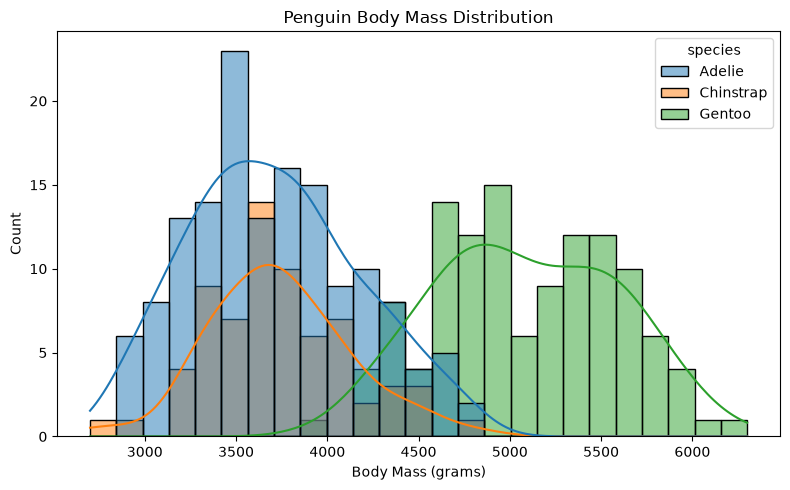

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='body_mass_g',
    hue='species',
    bins=25,
    kde=True
)

plt.title("Penguin Body Mass Distribution")
plt.xlabel("Body Mass (grams)")
plt.ylabel("Count")

plt.tight_layout()

plt.savefig("penguin_hist.png")
plt.show()

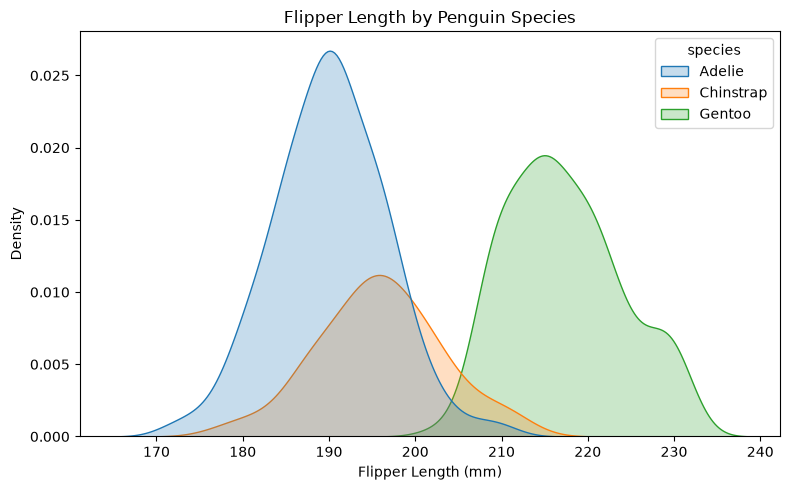

Axes-level return type: <class 'matplotlib.axes._axes.Axes'>


In [15]:
fig, ax = plt.subplots(figsize=(8, 5))

result1 = sns.kdeplot(
    data=df,
    x='flipper_length_mm',
    hue='species',
    fill=True,
    ax=ax
)

ax.set_title("Flipper Length by Penguin Species")
ax.set_xlabel("Flipper Length (mm)")
ax.set_ylabel("Density")

plt.tight_layout()

plt.savefig("flipper_axes_level.png")
plt.show()

print("Axes-level return type:", type(result1))

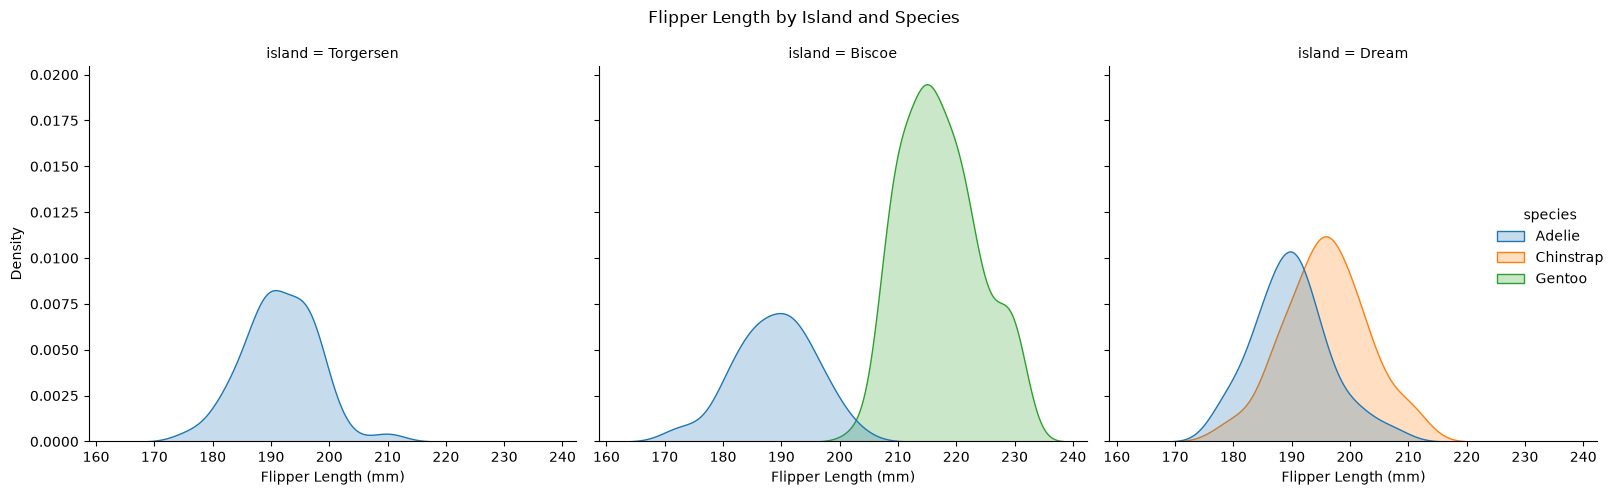

Figure-level return type: <class 'seaborn.axisgrid.FacetGrid'>


In [16]:
result2 = sns.displot(
    data=df,
    x='flipper_length_mm',
    kind='kde',
    hue='species',
    fill=True,
    col='island'
)

result2.set_axis_labels("Flipper Length (mm)", "Density")
result2.fig.suptitle("Flipper Length by Island and Species")

result2.fig.tight_layout()

result2.savefig("flipper_figure_level.png")

plt.show()

print("Figure-level return type:", type(result2))

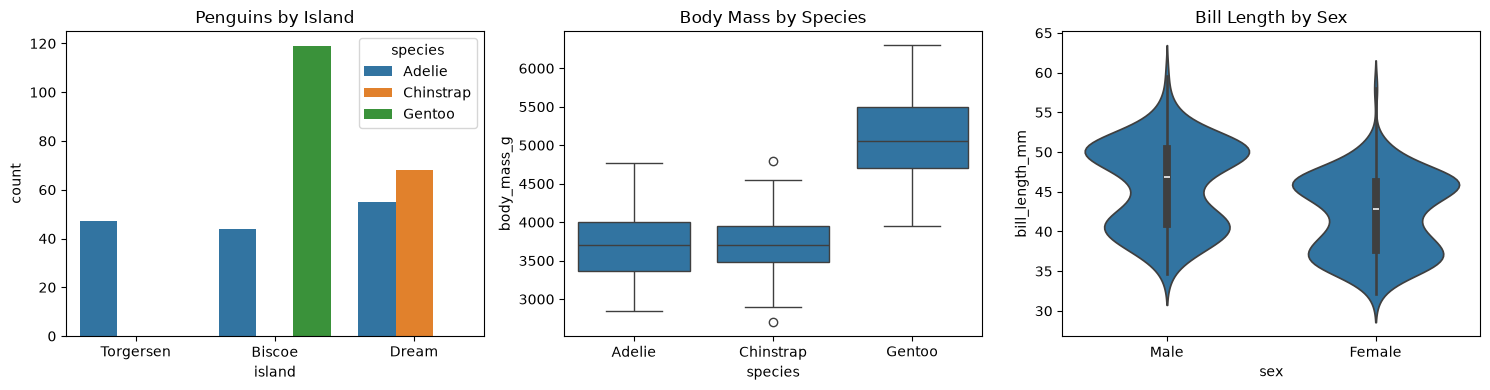

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Count plot
sns.countplot(
    data=df,
    x='island',
    hue='species',
    ax=axes[0]
)

axes[0].set_title("Penguins by Island")

# 2. Box plot
sns.boxplot(
    data=df,
    x='species',
    y='body_mass_g',
    ax=axes[1]
)

axes[1].set_title("Body Mass by Species")

# 3. Violin plot
sns.violinplot(
    data=df,
    x='sex',
    y='bill_length_mm',
    ax=axes[2]
)

axes[2].set_title("Bill Length by Sex")

plt.tight_layout()

plt.savefig("penguin_categorical.png")
plt.show()

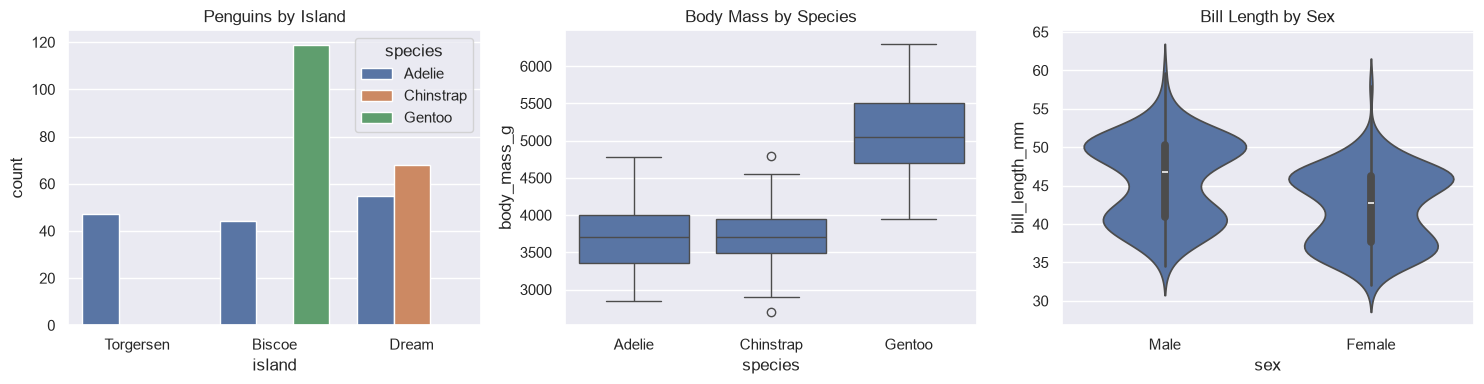

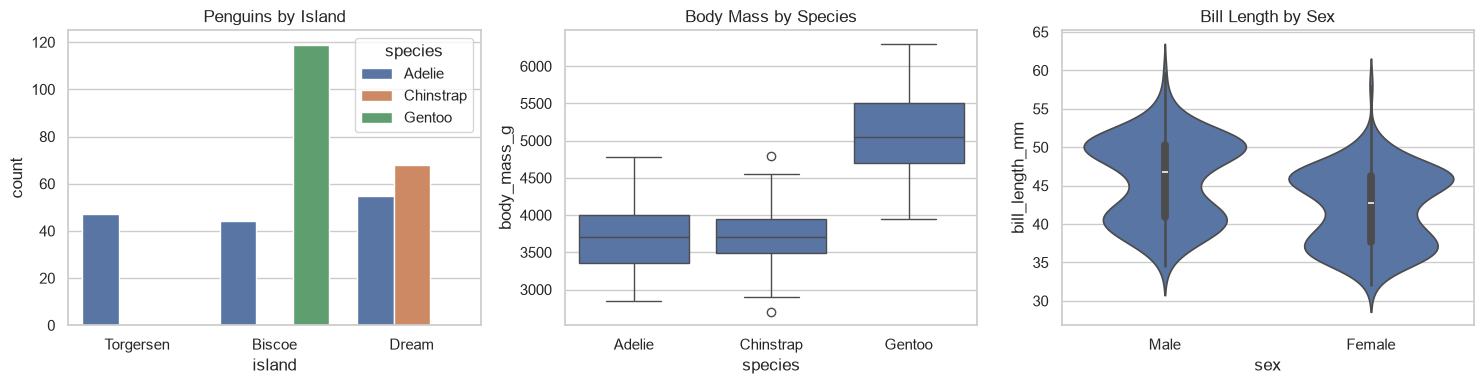

In [18]:
def make_panel(style, filename):

    # Set seaborn theme
    sns.set_theme(style=style)

    # Create one row with three plots
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # Count plot
    sns.countplot(
        data=df,
        x='island',
        hue='species',
        ax=axes[0]
    )

    axes[0].set_title("Penguins by Island")

    # Box plot
    sns.boxplot(
        data=df,
        x='species',
        y='body_mass_g',
        ax=axes[1]
    )

    axes[1].set_title("Body Mass by Species")

    # Violin plot
    sns.violinplot(
        data=df,
        x='sex',
        y='bill_length_mm',
        ax=axes[2]
    )

    axes[2].set_title("Bill Length by Sex")

    plt.tight_layout()

    # Save image
    plt.savefig(filename)

    plt.show()

    plt.close(fig)


# Create darkgrid panel
make_panel('darkgrid', 'penguin_darkgrid.png')

# Create whitegrid panel
make_panel('whitegrid', 'penguin_whitegrid.png')

In [19]:
print("Darkgrid file exists:",
      Path("penguin_darkgrid.png").exists())

print("Whitegrid file exists:",
      Path("penguin_whitegrid.png").exists())

assert Path("penguin_darkgrid.png").exists()
assert Path("penguin_whitegrid.png").exists()

print("Both files created successfully!")

Darkgrid file exists: True
Whitegrid file exists: True
Both files created successfully!
